# Original vs Universal drought-classification: event-level comparison

Plots the comparison summaries produced by `compare_methods.py`.

- **original** - each percentile threshold (5/10/20/30) applied independently; events re-identified per threshold; deficit measured vs that threshold.
- **universal** - single 30th-percentile baseline identifies events; each event gets one severity class from its minimum percentile; all metrics measured vs the 30th-percentile baseline.

In both, the `threshold` column is the bin: an *identification threshold* (original) or a *severity class* (universal).

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CMP_DIR = "/home/ryan/data/CONUS_drought_props/method_comparison"

agg = pd.read_csv(os.path.join(CMP_DIR, "cmp_aggregate_by_threshold.csv"))
per_site = pd.read_csv(os.path.join(CMP_DIR, "cmp_per_site_by_threshold.csv"), dtype={"site": str})
equiv = pd.read_csv(os.path.join(CMP_DIR, "cmp_equivalence_per_site.csv"), dtype={"site": str})

# BINS = [5, 10, 20, 30]
BINS = [30, 20, 10, 5]
METHODS = ["original", "universal"]
COLORS = {"original": "#c44e52", "universal": "#4c72b0"}
# agg.head()

## 1. Equivalence check: original `threshold=30` == universal (all classes)

The two methods use identical event identification (30th-pct baseline + pooling + 5-day minimum). The universal method only adds a class label, so the *set* of events must match. Points should lie on the 1:1 line.

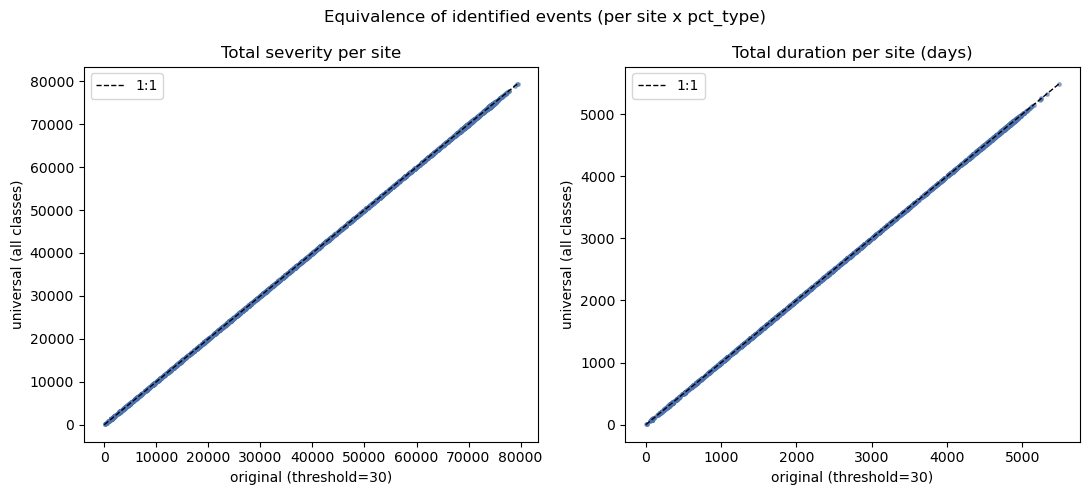

n_events         max|diff|=0  exact matches=7012/7012
total_duration   max|diff|=0  exact matches=7012/7012
total_severity   max|diff|=1.455e-11  exact matches=7012/7012


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, col, label in zip(
    axes,
    ["total_severity", "total_duration"],
    ["Total severity per site", "Total duration per site (days)"],
):
    x = equiv[f"{col}_orig30"]
    y = equiv[f"{col}_univ"]
    ax.scatter(x, y, s=6, alpha=0.3, color="#4c72b0")
    lim = [0, max(x.max(), y.max())]
    ax.plot(lim, lim, "k--", lw=1, label="1:1")
    ax.set_xlabel(f"original (threshold=30)")
    ax.set_ylabel("universal (all classes)")
    ax.set_title(label)
    ax.legend()
fig.suptitle("Equivalence of identified events (per site x pct_type)")
fig.tight_layout()
plt.show()

for col in ["n_events", "total_duration", "total_severity"]:
    d = (equiv[f"{col}_univ"] - equiv[f"{col}_orig30"]).abs()
    print(f"{col:16s} max|diff|={d.max():.4g}  exact matches={int((d<1e-6).sum())}/{len(equiv)}")

## 2. Headline: how severity / duration / counts vary across bins

Pooled over the four pct_types. The original method's severity *rises* toward milder thresholds (the counterintuitive deficit-fraction behaviour); the universal method's severity *falls* toward milder classes.

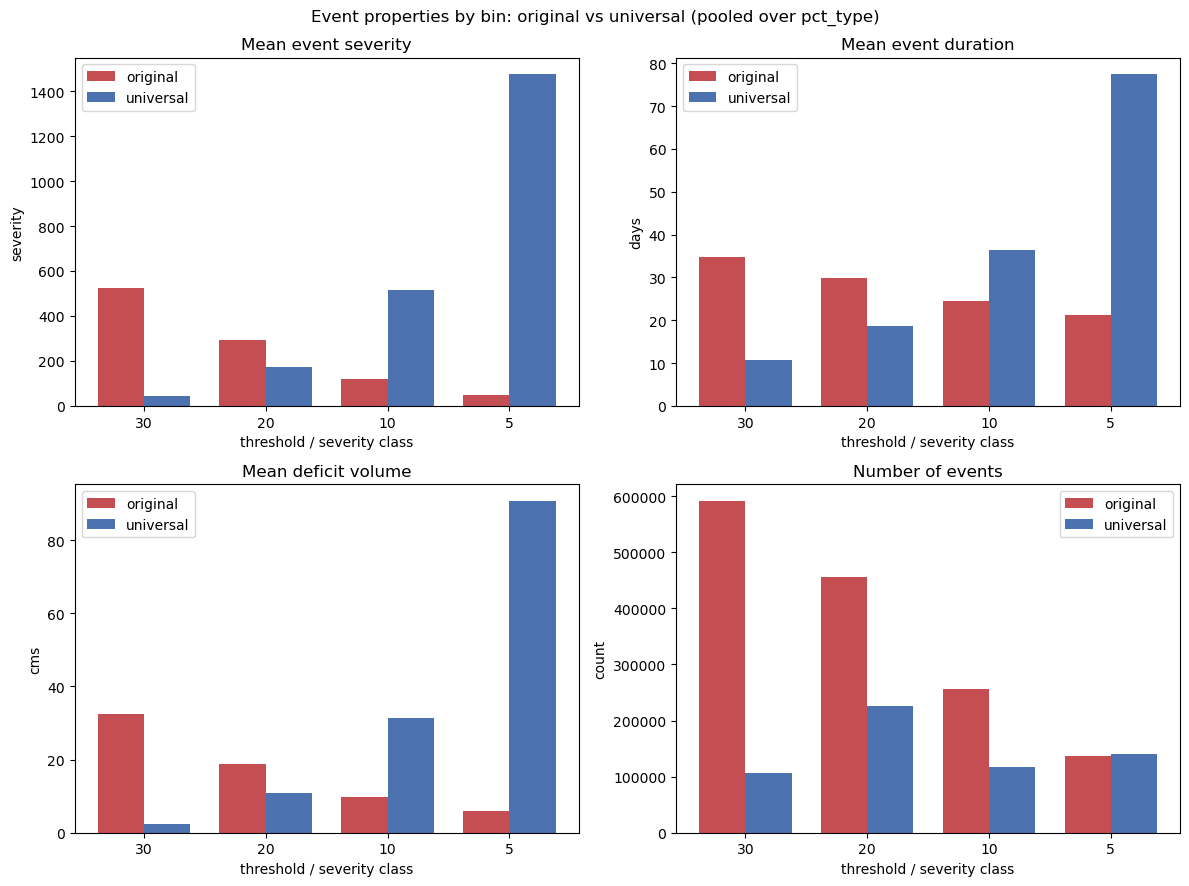

In [8]:
# Pool over pct_type by re-deriving event-weighted means from the aggregate totals.
pooled = (
    agg.groupby(["method", "threshold"])
    .agg(n_events=("n_events", "sum"),
         total_severity=("total_severity", "sum"),
         total_duration=("total_duration", "sum"),
         total_deficit_volume_cms=("total_deficit_volume_cms", "sum"))
    .reset_index()
)
pooled["mean_severity"] = pooled["total_severity"] / pooled["n_events"]
pooled["mean_duration"] = pooled["total_duration"] / pooled["n_events"]
pooled["mean_deficit_volume_cms"] = pooled["total_deficit_volume_cms"] / pooled["n_events"]

def grouped_bars(ax, metric, title, ylabel):
    width = 0.38
    x = np.arange(len(BINS))
    for i, m in enumerate(METHODS):
        vals = [pooled[(pooled.method == m) & (pooled.threshold == b)][metric].squeeze() for b in BINS]
        ax.bar(x + (i - 0.5) * width, vals, width, label=m, color=COLORS[m])
    ax.set_xticks(x)
    ax.set_xticklabels(BINS)
    ax.set_xlabel("threshold / severity class")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
grouped_bars(axes[0, 0], "mean_severity", "Mean event severity", "severity")
grouped_bars(axes[0, 1], "mean_duration", "Mean event duration", "days")
grouped_bars(axes[1, 0], "mean_deficit_volume_cms", "Mean deficit volume", "cms")
grouped_bars(axes[1, 1], "n_events", "Number of events", "count")
fig.suptitle("Event properties by bin: original vs universal (pooled over pct_type)")
fig.tight_layout()
plt.show()

## 3. Consistency across pct_types

Mean severity by bin, one panel per pct_type, to confirm the pattern holds for fixed (site) and variable (jd) percentiles and for obs/mod.

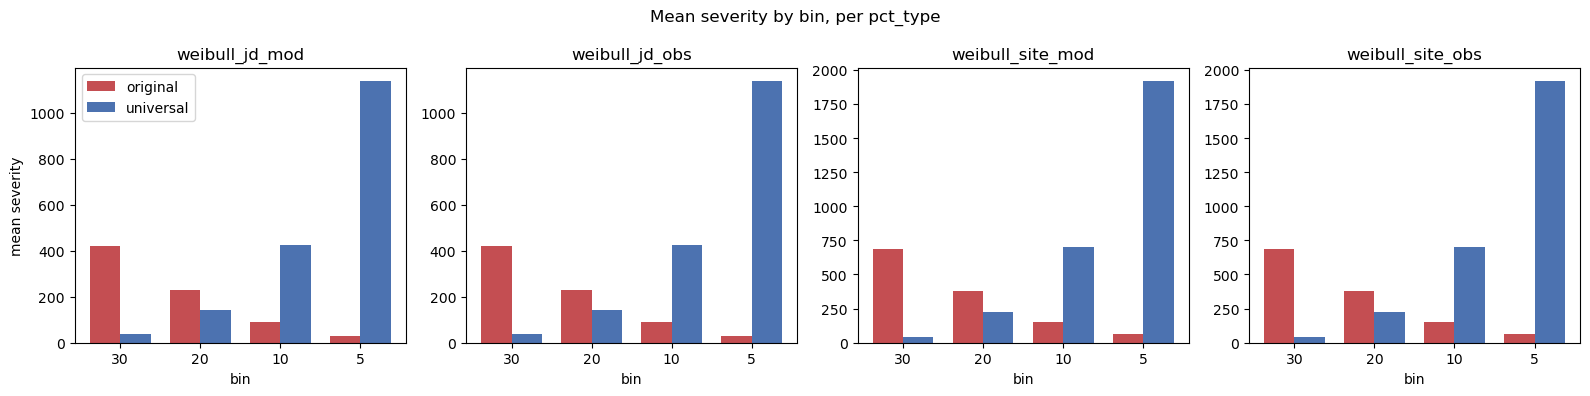

In [9]:
pct_types = sorted(agg["pct_type"].unique())
fig, axes = plt.subplots(1, len(pct_types), figsize=(4 * len(pct_types), 4), sharey=False)
if len(pct_types) == 1:
    axes = [axes]
for ax, pt in zip(axes, pct_types):
    sub = agg[agg.pct_type == pt]
    width = 0.38
    x = np.arange(len(BINS))
    for i, m in enumerate(METHODS):
        vals = [sub[(sub.method == m) & (sub.threshold == b)]["mean_severity"].squeeze() for b in BINS]
        vals = [v if np.ndim(v) == 0 else np.nan for v in vals]
        ax.bar(x + (i - 0.5) * width, vals, width, label=m, color=COLORS[m])
    ax.set_xticks(x); ax.set_xticklabels(BINS)
    ax.set_title(pt); ax.set_xlabel("bin")
axes[0].set_ylabel("mean severity"); axes[0].legend()
fig.suptitle("Mean severity by bin, per pct_type")
fig.tight_layout()
plt.show()

## 4. Per-site distributions

Across-site spread of per-site total severity in each bin (log scale), for one pct_type. Change `PCT_TYPE` to inspect others.

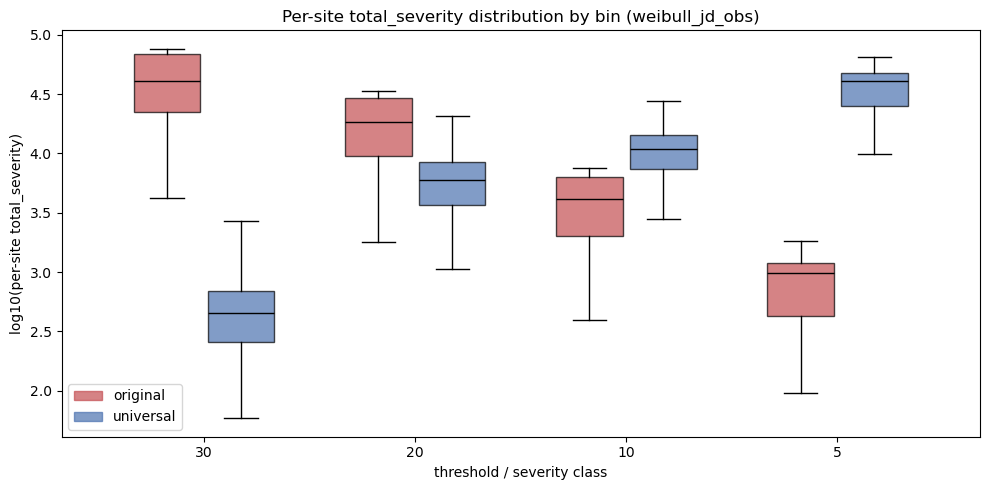

In [10]:
PCT_TYPE = "weibull_jd_obs"
metric = "total_severity"
sub = per_site[per_site.pct_type == PCT_TYPE]

fig, ax = plt.subplots(figsize=(10, 5))
positions, ticklabels = [], []
width = 0.35
for j, b in enumerate(BINS):
    for i, m in enumerate(METHODS):
        vals = sub[(sub.method == m) & (sub.threshold == b)][metric]
        vals = vals[vals > 0]
        pos = j + (i - 0.5) * width
        bp = ax.boxplot(np.log10(vals) if len(vals) else [np.nan], positions=[pos], widths=width * 0.9,
                        patch_artist=True, showfliers=False)
        for box in bp["boxes"]:
            box.set_facecolor(COLORS[m]); box.set_alpha(0.7)
        for med in bp["medians"]:
            med.set_color("black")
    positions.append(j); ticklabels.append(str(b))
ax.set_xticks(positions); ax.set_xticklabels(ticklabels)
ax.set_xlabel("threshold / severity class")
ax.set_ylabel(f"log10(per-site {metric})")
ax.set_title(f"Per-site {metric} distribution by bin ({PCT_TYPE})")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[m], alpha=0.7) for m in METHODS]
ax.legend(handles, METHODS)
fig.tight_layout()
plt.show()